# Importações

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [ ]:
uploads = files.upload()

Saving donqui.jpg to donqui.jpg


array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], dtype=uint8)
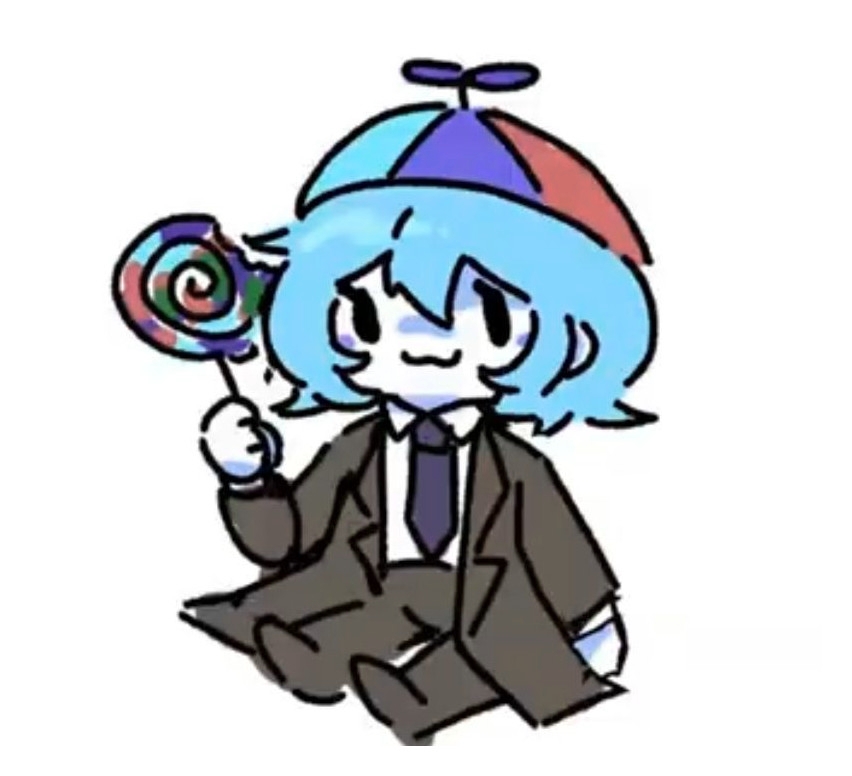

In [ ]:
img = cv2.imread('donqui.jpg')
img

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], dtype=uint8)
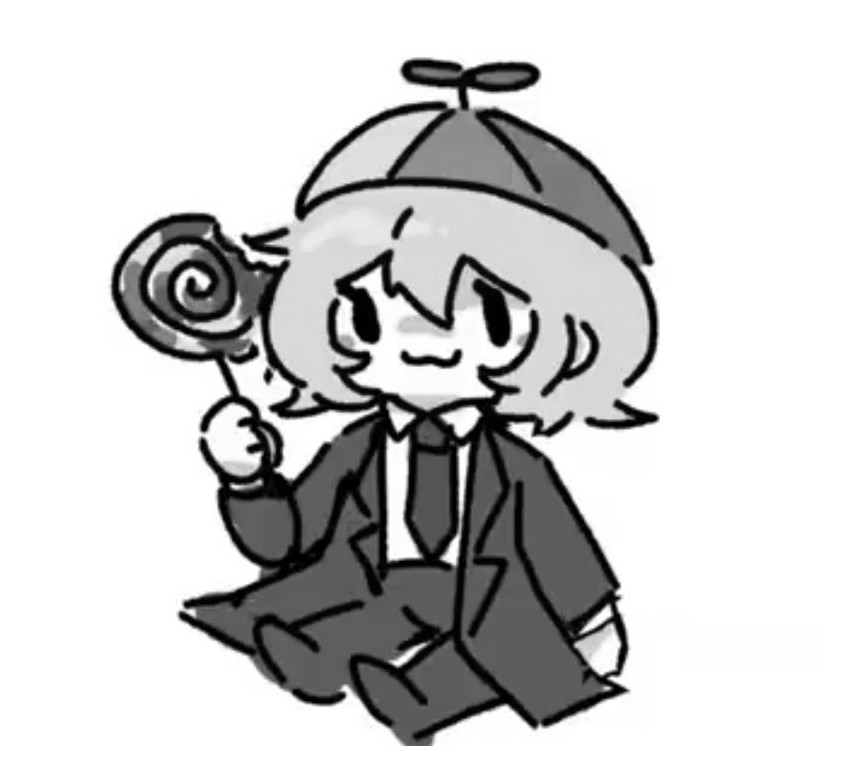

In [ ]:
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img_gray

In [ ]:
bits_amount_list = [8, 4, 2, 1]
qntz_imgs_array = {}

for b in bits_amount_list:
    levels = 2**b  # quantidade de níveis é 2 elevado a quantidade de bits na escala de cores
    step = 256 // levels  # degraus é inversamente proporcional a quantidade de níveis

    # divisão de pixeis
    quantized = (img_gray // step) * (255 // (levels - 1))
    qntz_imgs_array[b] = quantized.astype(np.uint8)

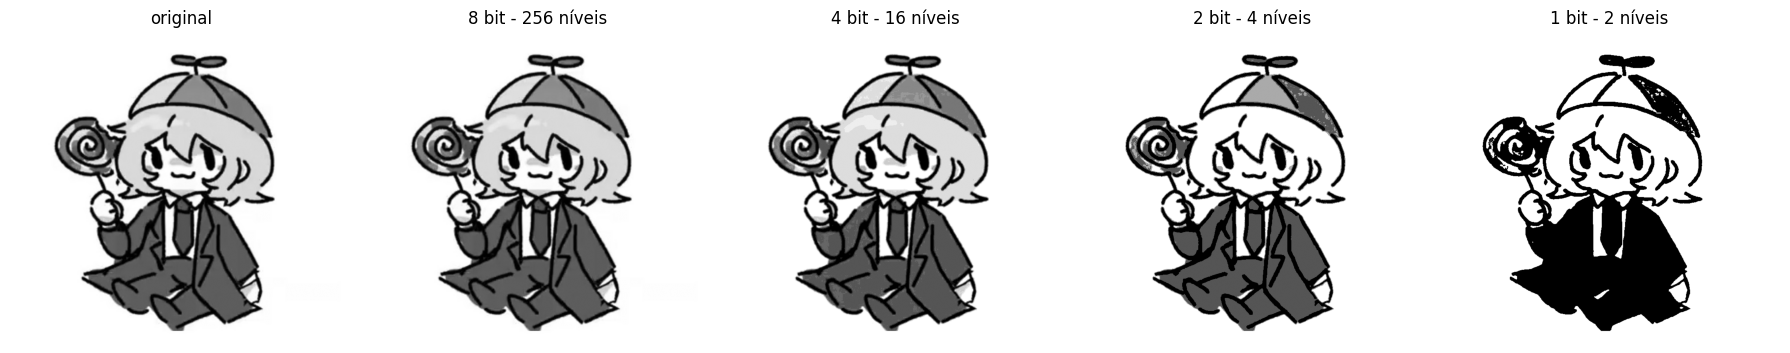

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

axes[0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("original")
axes[0].axis('off')

# imagens quantizadas
for ax, b in zip(axes[1:], bits_amount_list):
    axes_idx = bits_amount_list.index(b) + 1
    axes[axes_idx].imshow(qntz_imgs_array[b], cmap='gray', vmin=0, vmax=255)
    axes[axes_idx].set_title(f"{b} bit - {2**b} níveis")
    axes[axes_idx].axis('off')

plt.tight_layout()

# 4. Salvar a figura gerada
plt.savefig('quantizado.png', bbox_inches='tight', dpi=300)
plt.show()

Q: O que acontece com os detalhes e com as transições de intensidade da imagem à medida que reduzimos o número de bits?

R: com menos bits, as transições de intensidade ficam mais bruscas e os detalhes menos detalhados, por consequencia da menor quantidade de bits disponiveis para mostrar informações importantes.